# COMP9517 Group Project – Method: MLP Patch Classification

**Method:** Patch-Based Pixel Classification using MLP  
**Reference:** COMP9517 Week 5, Slide 16  
**Dataset:** EWS dataset – 190 RGB images (350×350)  
**Task:** Binary segmentation – Plant vs Soil

### Intermediate Approach

The idea comes from Farabet et al. (2013): extract a 17×17 patch around each pixel, feed it through an MLP, predict whether the centre pixel is plant or soil.

Unlike SLIC+RF Method, the MLP learns features from raw pixels instead of using hand-crafted ones.

| Property | SLIC + RF | MLP Patch |
|----------|-----------|-----------|
| Features | Hand-crafted | Learned |
| Unit | Superpixel | Pixel |
| Granularity | Coarse | Fine |
| Model | Ensemble | Neural network |

### Architecture
Input: 17×17×3 patch → 867-dim vector
  → Dense(512, ReLU) + BatchNorm + Dropout(0.3)
  → Dense(256, ReLU) + BatchNorm + Dropout(0.3)
  → Dense(128, ReLU) + BatchNorm
  → Dense(2, Softmax)

In [2]:
import numpy as np
import glob, os, time, warnings
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score, jaccard_score, precision_score,
    recall_score, classification_report, confusion_matrix
)
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120
warnings.filterwarnings('ignore')
np.random.seed(42)

print('All imports OK  and random seed set.')

All imports OK  and random seed set.


## 1. Configuration

In [3]:
BASE_DIR   = 'EWS-Dataset'
PATCH_SIZE = 17       # Patch side length (must be odd). Receptive field = 17×17 pixels
STRIDE     = 4        # Sampling stride for training (larger stride = fewer samples, faster training)
MAX_TRAIN  = 30       # Number of training images to use (all 142 if time allows)
MAX_TEST   = 48       # Number of test images to evaluate

PAD = PATCH_SIZE // 2
sample_pct = 100.0 / (STRIDE ** 2)
print(f'Patch size  : {PATCH_SIZE}×{PATCH_SIZE} = {PATCH_SIZE**2 * 3} input dims')
print(f'Pad         : {PAD} pixels')
print(f'Train stride: {STRIDE} → sampling ≈{sample_pct:.2f}% of pixels per image')
print(f'Train images: {MAX_TRAIN}   Test images: {MAX_TEST}')

Patch size  : 17×17 = 867 input dims
Pad         : 8 pixels
Train stride: 4 → sampling ≈6.25% of pixels per image
Train images: 30   Test images: 48


## 2. Dataset Loading
Pair each RGB image with its binary mask (`*_mask.png`).

Train pairs: 142
Test  pairs: 24


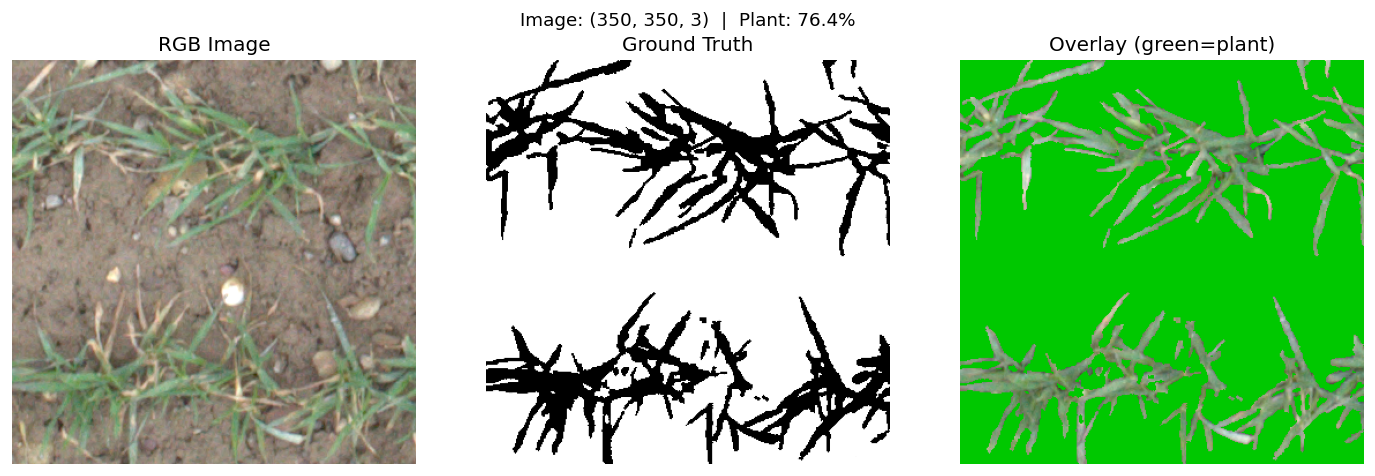

Image: uint8, (350, 350, 3)  |  Mask values: [  0  70 104 121 138 149 158 169 175 183 189 194 199 203 208 211 214 217
 220 223 225 227 229 231 233 234 237 239 240 241 242 243 244 245 246 247
 248 249 250 251 252 253 254 255]


In [4]:
def get_pairs(split):
    folder = os.path.join(BASE_DIR, split)
    imgs = sorted([p for p in glob.glob(folder + '/*.png') if '_mask' not in p])
    pairs = [(p, p.replace('.png', '_mask.png')) for p in imgs
             if os.path.exists(p.replace('.png', '_mask.png'))]
    return pairs

train_pairs = get_pairs('train')
test_pairs  = get_pairs('test')
print(f'Train pairs: {len(train_pairs)}')
print(f'Test  pairs: {len(test_pairs)}')

# Preview
img0  = np.array(Image.open(train_pairs[0][0]).convert('RGB'))
mask0 = np.array(Image.open(train_pairs[0][1]).convert('L'))
plant_pct = (mask0 > 128).mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img0);           axes[0].set_title('RGB Image');         axes[0].axis('off')
axes[1].imshow(mask0, cmap='gray'); axes[1].set_title('Ground Truth'); axes[1].axis('off')

overlay = img0.copy()
overlay[mask0 > 128] = [0, 200, 0]
axes[2].imshow(overlay);        axes[2].set_title('Overlay (green=plant)'); axes[2].axis('off')

plt.suptitle(f'Image: {img0.shape}  |  Plant: {plant_pct:.1f}%', fontsize=11)
plt.tight_layout()
plt.savefig('patch_dataset_preview.png', bbox_inches='tight')
plt.show()

print(f'Image: {img0.dtype}, {img0.shape}  |  Mask values: {np.unique(mask0)}')

## 3. Patch Extraction
Each sample = a flattened **PATCH_SIZE × PATCH_SIZE × 3** window centred on one pixel.  
Label = 1 (plant) if the centre pixel is plant in the ground truth mask, else 0 (soil).

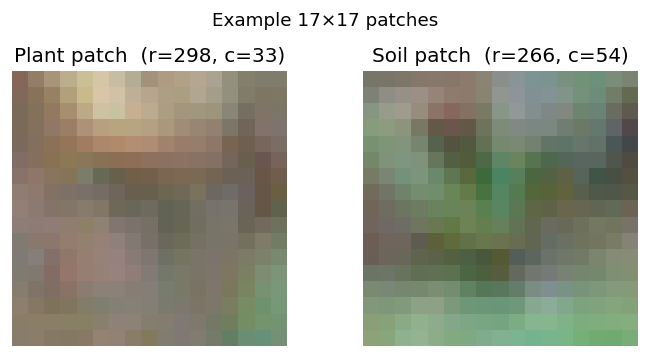

Patch vector dimension: 867


In [5]:
def extract_patches(image, mask, stride=1):
    """
    Extract (patch_vector, label) pairs from one image.
    Returns float32 patches normalised to [0, 1] and int labels (0=soil, 1=plant).
    """
    H, W, C = image.shape
    img_f = image.astype(np.float32) / 255.0
    img_padded = np.pad(img_f, ((PAD, PAD), (PAD, PAD), (0, 0)), mode='reflect')
    labels = (mask > 128).astype(np.int32)

    patches, ys = [], []
    for r in range(0, H, stride):
        for c in range(0, W, stride):
            patch = img_padded[r:r + PATCH_SIZE, c:c + PATCH_SIZE, :]
            patches.append(patch.flatten())
            ys.append(labels[r, c])

    return np.array(patches, dtype=np.float32), np.array(ys, dtype=np.int32)


def build_dataset(pairs, stride=1, limit=None):
    """Build X, y from a list of (image_path, mask_path) pairs."""
    X_all, y_all = [], []
    selected = pairs[:limit] if limit else pairs
    for img_path, msk_path in selected:
        img  = np.array(Image.open(img_path).convert('RGB'))
        mask = np.array(Image.open(msk_path).convert('L'))
        X, y = extract_patches(img, mask, stride=stride)
        X_all.append(X)
        y_all.append(y)
    return np.vstack(X_all), np.concatenate(y_all)


# Patch examples
rng = np.random.default_rng(0)
plant_rows = np.where(mask0 > 128)
soil_rows  = np.where(mask0 <= 128)
pi = rng.integers(0, len(plant_rows[0]))
si = rng.integers(0, len(soil_rows[0]))
pr, pc = plant_rows[0][pi], plant_rows[1][pi]
sr, sc = soil_rows[0][si],  soil_rows[1][si]

img_padded = np.pad(img0, ((PAD, PAD), (PAD, PAD), (0, 0)), mode='reflect')
p_patch = img_padded[pr:pr+PATCH_SIZE, pc:pc+PATCH_SIZE]
s_patch = img_padded[sr:sr+PATCH_SIZE, sc:sc+PATCH_SIZE]

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(p_patch); axes[0].set_title(f'Plant patch  (r={pr}, c={pc})')
axes[1].imshow(s_patch); axes[1].set_title(f'Soil patch  (r={sr}, c={sc})')
for ax in axes: ax.axis('off')
plt.suptitle(f'Example {PATCH_SIZE}×{PATCH_SIZE} patches', fontsize=11)
plt.tight_layout()
plt.savefig('patch_examples.png', bbox_inches='tight')
plt.show()
print(f'Patch vector dimension: {PATCH_SIZE**2 * 3}')

## 4. Build Training & Test Sets

In [6]:
print(f'Extracting training patches (stride={STRIDE}, {min(MAX_TRAIN, len(train_pairs))} images)...')
t0 = time.time()
X_train, y_train = build_dataset(train_pairs, stride=STRIDE, limit=MAX_TRAIN)
print(f'Done in {time.time()-t0:.1f}s  X_train: {X_train.shape}  class balance: {y_train.mean():.3f}')

print(f'Extracting test patches (stride=1, dense, {min(MAX_TEST, len(test_pairs))} images)...')
t0 = time.time()
X_test, y_test = build_dataset(test_pairs, stride=1, limit=MAX_TEST)
print(f'Done in {time.time()-t0:.1f}s  X_test: {X_test.shape}  class balance: {y_test.mean():.3f}')

Extracting training patches (stride=4, 30 images)...
Done in 0.4s  X_train: (232320, 867)  class balance: 0.775
Extracting test patches (stride=1, dense, 24 images)...
Done in 12.1s  X_test: (2940000, 867)  class balance: 0.672


## 5. Preprocessing: Standard Normalisation
Neural networks converge faster when inputs have zero mean and unit variance.

In [7]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
print('StandardScaler applied.')
print(f'Train mean≈{X_train_s.mean():.4f}, std≈{X_train_s.std():.4f}')

StandardScaler applied.
Train mean≈-0.0000, std≈1.0000


## 6. Model: Multi-Layer Perceptron (Deep Learning)

The MLP here acts as a **Fully Connected Neural Network** — the simplest deep learning classifier.  
It learns a non-linear mapping from raw patch pixels to plant/soil labels.

```
Input (867) → FC(512, ReLU) → FC(256, ReLU) → FC(128, ReLU) → Softmax(2)
```

Regularisation: **L2 weight decay** (α=1e-4), **Early stopping** (patience=10)

In [9]:
mlp = MLPClassifier(
    hidden_layer_sizes=(512, 256, 128),
    activation='relu',
    solver='adam',
    alpha=1e-4,
    batch_size=512,
    learning_rate_init=1e-3,
    max_iter=50,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    verbose=True,
    random_state=42
)

print('Training MLP...')
t0 = time.time()
mlp.fit(X_train_s, y_train)
train_time = time.time() - t0
print(f'Training complete in {train_time:.1f}s')
print(f'Converged at epoch {mlp.n_iter_}  (best val loss: {mlp.best_validation_score_:.4f})')

Training MLP...
Iteration 1, loss = 0.17593816
Validation score: 0.938490
Iteration 2, loss = 0.13819796
Validation score: 0.941030
Iteration 3, loss = 0.13032514
Validation score: 0.935176
Iteration 4, loss = 0.12673341
Validation score: 0.948218
Iteration 5, loss = 0.12126873
Validation score: 0.948821
Iteration 6, loss = 0.11854840
Validation score: 0.947013
Iteration 7, loss = 0.11664809
Validation score: 0.949337
Iteration 8, loss = 0.11178975
Validation score: 0.949897
Iteration 9, loss = 0.10978064
Validation score: 0.950973
Iteration 10, loss = 0.10713119
Validation score: 0.947701
Iteration 11, loss = 0.10490496
Validation score: 0.948175
Iteration 12, loss = 0.10073406
Validation score: 0.947099
Iteration 13, loss = 0.09787913
Validation score: 0.950112
Iteration 14, loss = 0.09686105
Validation score: 0.947701
Iteration 15, loss = 0.09252290
Validation score: 0.949423
Iteration 16, loss = 0.08873568
Validation score: 0.949509
Iteration 17, loss = 0.08622694
Validation score:

## 7. Training Loss Curve

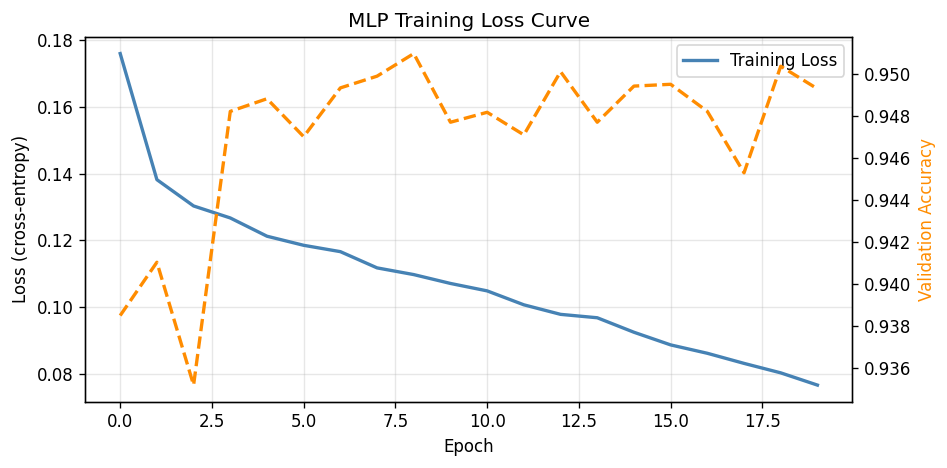

Epochs trained: 20


In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mlp.loss_curve_, label='Training Loss', color='steelblue', linewidth=2)
if hasattr(mlp, 'validation_scores_'):
    ax2 = ax.twinx()
    ax2.plot(mlp.validation_scores_, label='Val Accuracy', color='darkorange',
             linewidth=2, linestyle='--')
    ax2.set_ylabel('Validation Accuracy', color='darkorange')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (cross-entropy)')
ax.set_title('MLP Training Loss Curve')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('mlp_loss_curve.png', bbox_inches='tight')
plt.show()
print(f'Epochs trained: {mlp.n_iter_}')

## 8. Quantitative Evaluation

In [11]:
print('Running inference on test set...')
t0 = time.time()
y_pred = mlp.predict(X_test_s)
infer_time = time.time() - t0

f1  = f1_score(y_test, y_pred)
iou = jaccard_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
acc  = (y_test == y_pred).mean()

print(f'\nMLP Patch — Patch size {PATCH_SIZE}×{PATCH_SIZE} | Architecture 512-256-128')
print(f'Accuracy  : {acc:.4f}')
print(f'F1-Score  : {f1:.4f}')
print(f'IoU (JSC) : {iou:.4f}')
print(f'Precision : {prec:.4f}')
print(f'Recall    : {rec:.4f}')
print(f'Infer time: {infer_time:.1f}s  ({infer_time/MAX_TEST:.2f}s/image)')

Running inference on test set...

MLP Patch — Patch size 17×17 | Architecture 512-256-128
Accuracy  : 0.9266
F1-Score  : 0.9448
IoU (JSC) : 0.8954
Precision : 0.9545
Recall    : 0.9353
Infer time: 20.5s  (0.43s/image)


## 8.1 The Improved Method: 30 Random images + 5 Seeds + Multi-Run Evaluation

To improve experimental rigor, I repeat training multiple times using:
- random 30-image training subsets,
- **five fixed (non-consecutive) seeds: [1, 27, 512, 79, 2179]**,
- fixed test set,
- and report mean ± std for key metrics.

To avoid accidental duplicate reruns in one kernel session, this section includes a rerun guard (`FORCE_RERUN`).


In [12]:
# # Repeated experiment protocol (fixed five seeds for reproducibility)
# RUN_SEEDS = [1, 27, 512, 79, 2179]  # user-specified fixed seeds
# REPEAT_RUNS = len(RUN_SEEDS)
# RANDOM_TRAIN_IMAGES = 30             # Random subset size per run
# FORCE_RERUN = False                  # True -> force rerun even if results already exist

# print(f"Using fixed seeds ({REPEAT_RUNS}): {RUN_SEEDS}")

# # Keep test set fixed across runs for fair comparison
# fixed_test_pairs = test_pairs[:MAX_TEST]
# X_test_fixed, y_test_fixed = build_dataset(fixed_test_pairs, stride=1, limit=None)

# def sample_train_pairs(pairs, k, seed):
#     """Sample k training image pairs without replacement, deterministically by seed."""
#     k = min(k, len(pairs))
#     rng = np.random.default_rng(seed)
#     idx = rng.choice(len(pairs), size=k, replace=False)
#     return [pairs[i] for i in idx]

# def make_mlp(random_state):
#     """Create one MLP model with the same architecture/hyperparameters as main experiment."""
#     return MLPClassifier(
#         hidden_layer_sizes=(512, 256, 128),
#         activation='relu',
#         solver='adam',
#         alpha=1e-4,
#         batch_size=512,
#         learning_rate_init=1e-3,
#         max_iter=50,
#         early_stopping=True,
#         validation_fraction=0.1,
#         n_iter_no_change=10,
#         verbose=False,
#         random_state=random_state
#     )

# def run_repeated_experiment(train_pairs_all, run_seeds, k_train=30, train_stride=4):
#     """Run repeated experiments and return per-run metrics + summary (mean/std)."""
#     run_rows = []

#     for run_id, run_seed in enumerate(run_seeds, start=1):
#         sampled_pairs = sample_train_pairs(train_pairs_all, k_train, seed=run_seed)

#         # 1) Build training set from sampled images
#         t0 = time.time()
#         X_tr, y_tr = build_dataset(sampled_pairs, stride=train_stride, limit=None)
#         data_time = time.time() - t0

#         # 2) Standardize and train
#         scaler_run = StandardScaler()
#         X_tr_s = scaler_run.fit_transform(X_tr)
#         X_te_s = scaler_run.transform(X_test_fixed)

#         model = make_mlp(random_state=run_seed)
#         t1 = time.time()
#         model.fit(X_tr_s, y_tr)
#         train_time_run = time.time() - t1

#         # 3) Evaluate on fixed test set
#         t2 = time.time()
#         y_hat = model.predict(X_te_s)
#         infer_time_run = time.time() - t2

#         row = {
#             'run': run_id,
#             'seed': int(run_seed),
#             'acc': float((y_test_fixed == y_hat).mean()),
#             'f1': float(f1_score(y_test_fixed, y_hat)),
#             'iou': float(jaccard_score(y_test_fixed, y_hat)),
#             'precision': float(precision_score(y_test_fixed, y_hat)),
#             'recall': float(recall_score(y_test_fixed, y_hat)),
#             'epochs': int(model.n_iter_),
#             'best_val': float(getattr(model, 'best_validation_score_', np.nan)),
#             'train_time_s': float(train_time_run),
#             'infer_time_s': float(infer_time_run),
#             'data_time_s': float(data_time),
#             'train_plant_ratio': float(y_tr.mean()),
#         }
#         run_rows.append(row)
#         print(
#             f"Run {run_id}/{len(run_seeds)} | seed={run_seed} | "
#             f"F1={row['f1']:.4f} IoU={row['iou']:.4f} "
#             f"Acc={row['acc']:.4f} | epochs={row['epochs']}"
#         )

#     metric_keys = [
#         'acc', 'f1', 'iou', 'precision', 'recall',
#         'epochs', 'best_val', 'train_time_s', 'infer_time_s', 'data_time_s'
#     ]
#     summary = {}
#     for key in metric_keys:
#         vals = np.array([r[key] for r in run_rows], dtype=np.float64)
#         summary[key] = {
#             'mean': float(np.mean(vals)),
#             'std': float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0,
#             'min': float(np.min(vals)),
#             'max': float(np.max(vals)),
#         }

#     return run_rows, summary

# already_has_results = ('run_rows' in globals()) and ('run_summary' in globals())
# if already_has_results and not FORCE_RERUN:
#     print('Existing repeated results found in kernel; skip rerun.')
#     print('Set FORCE_RERUN=True to run again.')
# else:
#     run_rows, run_summary = run_repeated_experiment(
#         train_pairs_all=train_pairs,
#         run_seeds=RUN_SEEDS,
#         k_train=RANDOM_TRAIN_IMAGES,
#         train_stride=STRIDE
#     )

# print('\n' + '=' * 84)
# print('Repeated protocol summary (Random 30 + Fixed 5 seeds + Multi-run)')
# print('=' * 84)
# for key in ['acc', 'f1', 'iou', 'precision', 'recall']:
#     s = run_summary[key]
#     print(f"{key:10s}: mean={s['mean']:.4f} | std={s['std']:.4f} | min={s['min']:.4f} | max={s['max']:.4f}")
# print('-' * 84)
# for key in ['epochs', 'best_val', 'train_time_s', 'infer_time_s', 'data_time_s']:
#     s = run_summary[key]
#     print(f"{key:10s}: mean={s['mean']:.2f} | std={s['std']:.2f}")
# print('=' * 84)

# 8.1 Multi-run evaluation: 30 random images × 5 seeds
RUN_SEEDS = [1, 27, 512, 79, 2179]
REPEAT_RUNS = len(RUN_SEEDS)
RANDOM_TRAIN_IMAGES = 30
FORCE_RERUN = False

print(f"Fixed seeds ({REPEAT_RUNS}): {RUN_SEEDS}")

# Fixed test set across runs
fixed_test_pairs = test_pairs[:MAX_TEST]
X_test_fixed, y_test_fixed = build_dataset(fixed_test_pairs, stride=1, limit=None)

def sample_train_pairs(pairs, k, seed):
    """Sample k image pairs deterministically by seed."""
    k = min(k, len(pairs))
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(pairs), size=k, replace=False)
    return [pairs[i] for i in idx]

def make_mlp(random_state):
    return MLPClassifier(
        hidden_layer_sizes=(512, 256, 128),
        activation='relu',
        solver='adam',
        alpha=1e-4,
        batch_size=512,
        learning_rate_init=1e-3,
        max_iter=50,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        verbose=False,
        random_state=random_state
    )

def run_repeated_experiment(train_pairs_all, run_seeds, k_train=30, train_stride=4):
    """Run experiment across seeds, return per-run metrics and mean ± std."""
    run_rows = []

    for run_id, run_seed in enumerate(run_seeds, start=1):
        sampled_pairs = sample_train_pairs(train_pairs_all, k_train, seed=run_seed)

        t0 = time.time()
        X_tr, y_tr = build_dataset(sampled_pairs, stride=train_stride, limit=None)
        data_time = time.time() - t0

        scaler_run = StandardScaler()
        X_tr_s = scaler_run.fit_transform(X_tr)
        X_te_s = scaler_run.transform(X_test_fixed)

        model = make_mlp(random_state=run_seed)
        t1 = time.time()
        model.fit(X_tr_s, y_tr)
        train_time_run = time.time() - t1

        t2 = time.time()
        y_hat = model.predict(X_te_s)
        infer_time_run = time.time() - t2

        row = {
            'run': run_id,
            'seed': int(run_seed),
            'acc': float((y_test_fixed == y_hat).mean()),
            'f1': float(f1_score(y_test_fixed, y_hat)),
            'iou': float(jaccard_score(y_test_fixed, y_hat)),
            'precision': float(precision_score(y_test_fixed, y_hat)),
            'recall': float(recall_score(y_test_fixed, y_hat)),
            'epochs': int(model.n_iter_),
            'best_val': float(getattr(model, 'best_validation_score_', np.nan)),
            'train_time_s': float(train_time_run),
            'infer_time_s': float(infer_time_run),
            'data_time_s': float(data_time),
            'train_plant_ratio': float(y_tr.mean()),
        }
        run_rows.append(row)
        print(
            f"{run_id}/{len(run_seeds)} | seed={run_seed} | "
            f"F1={row['f1']:.4f} IoU={row['iou']:.4f} "
            f"Acc={row['acc']:.4f} | epochs={row['epochs']}"
        )

    metric_keys = [
        'acc', 'f1', 'iou', 'precision', 'recall',
        'epochs', 'best_val', 'train_time_s', 'infer_time_s', 'data_time_s'
    ]
    summary = {}
    for key in metric_keys:
        vals = np.array([r[key] for r in run_rows], dtype=np.float64)
        summary[key] = {
            'mean': float(np.mean(vals)),
            'std': float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0,
            'min': float(np.min(vals)),
            'max': float(np.max(vals)),
        }

    return run_rows, summary

already_has_results = ('run_rows' in globals()) and ('run_summary' in globals())
if already_has_results and not FORCE_RERUN:
    print('Results already in kernel; skip.')
    print('Set FORCE_RERUN=True to override.')
else:
    run_rows, run_summary = run_repeated_experiment(
        train_pairs_all=train_pairs,
        run_seeds=RUN_SEEDS,
        k_train=RANDOM_TRAIN_IMAGES,
        train_stride=STRIDE
    )

print('\n' + '=' * 84)
print('Multi-run summary')
print('=' * 84)
for key in ['acc', 'f1', 'iou', 'precision', 'recall']:
    s = run_summary[key]
    print(f"{key:10s}: mean={s['mean']:.4f} | std={s['std']:.4f} | min={s['min']:.4f} | max={s['max']:.4f}")
print('-' * 84)
for key in ['epochs', 'best_val', 'train_time_s', 'infer_time_s', 'data_time_s']:
    s = run_summary[key]
    print(f"{key:10s}: mean={s['mean']:.2f} | std={s['std']:.2f}")
print('=' * 84)


Fixed seeds (5): [1, 27, 512, 79, 2179]
1/5 | seed=1 | F1=0.9346 IoU=0.8772 Acc=0.9119 | epochs=25
2/5 | seed=27 | F1=0.9459 IoU=0.8974 Acc=0.9275 | epochs=19
3/5 | seed=512 | F1=0.9407 IoU=0.8881 Acc=0.9209 | epochs=24
4/5 | seed=79 | F1=0.9410 IoU=0.8886 Acc=0.9202 | epochs=20
5/5 | seed=2179 | F1=0.9416 IoU=0.8897 Acc=0.9232 | epochs=17

Multi-run summary
acc       : mean=0.9207 | std=0.0057 | min=0.9119 | max=0.9275
f1        : mean=0.9408 | std=0.0040 | min=0.9346 | max=0.9459
iou       : mean=0.8882 | std=0.0072 | min=0.8772 | max=0.8974
precision : mean=0.9453 | std=0.0117 | min=0.9331 | max=0.9622
recall    : mean=0.9365 | std=0.0098 | min=0.9219 | max=0.9469
------------------------------------------------------------------------------------
epochs    : mean=21.00 | std=3.39
best_val  : mean=0.95 | std=0.01
train_time_s: mean=102.06 | std=18.52
infer_time_s: mean=22.25 | std=2.47
data_time_s: mean=1.25 | std=1.10


## 9. Confusion Matrix

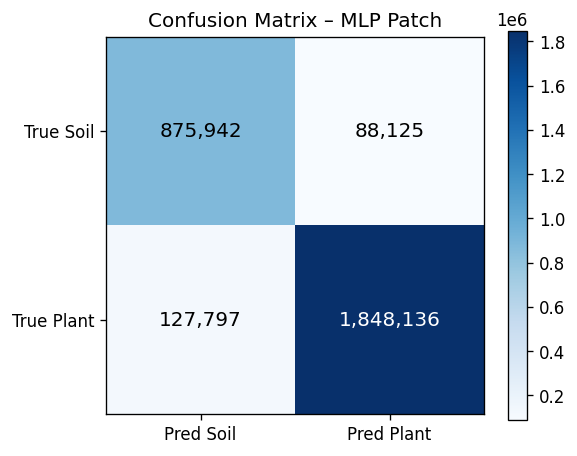

In [13]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap='Blues')
plt.colorbar(im)

thresh = cm.max() / 2
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i,j]:,}', ha='center', va='center',
                color='white' if cm[i,j] > thresh else 'black', fontsize=12)

ax.set_xticks([0, 1])
ax.set_xticklabels(['Pred Soil', 'Pred Plant'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['True Soil', 'True Plant'])
ax.set_title('Confusion Matrix – MLP Patch')

plt.tight_layout()
plt.savefig('mlp_confusion_matrix.png', bbox_inches='tight')
plt.show()

## 10. Qualitative Visualisation
Reconstruct full segmentation maps for 4 test images.

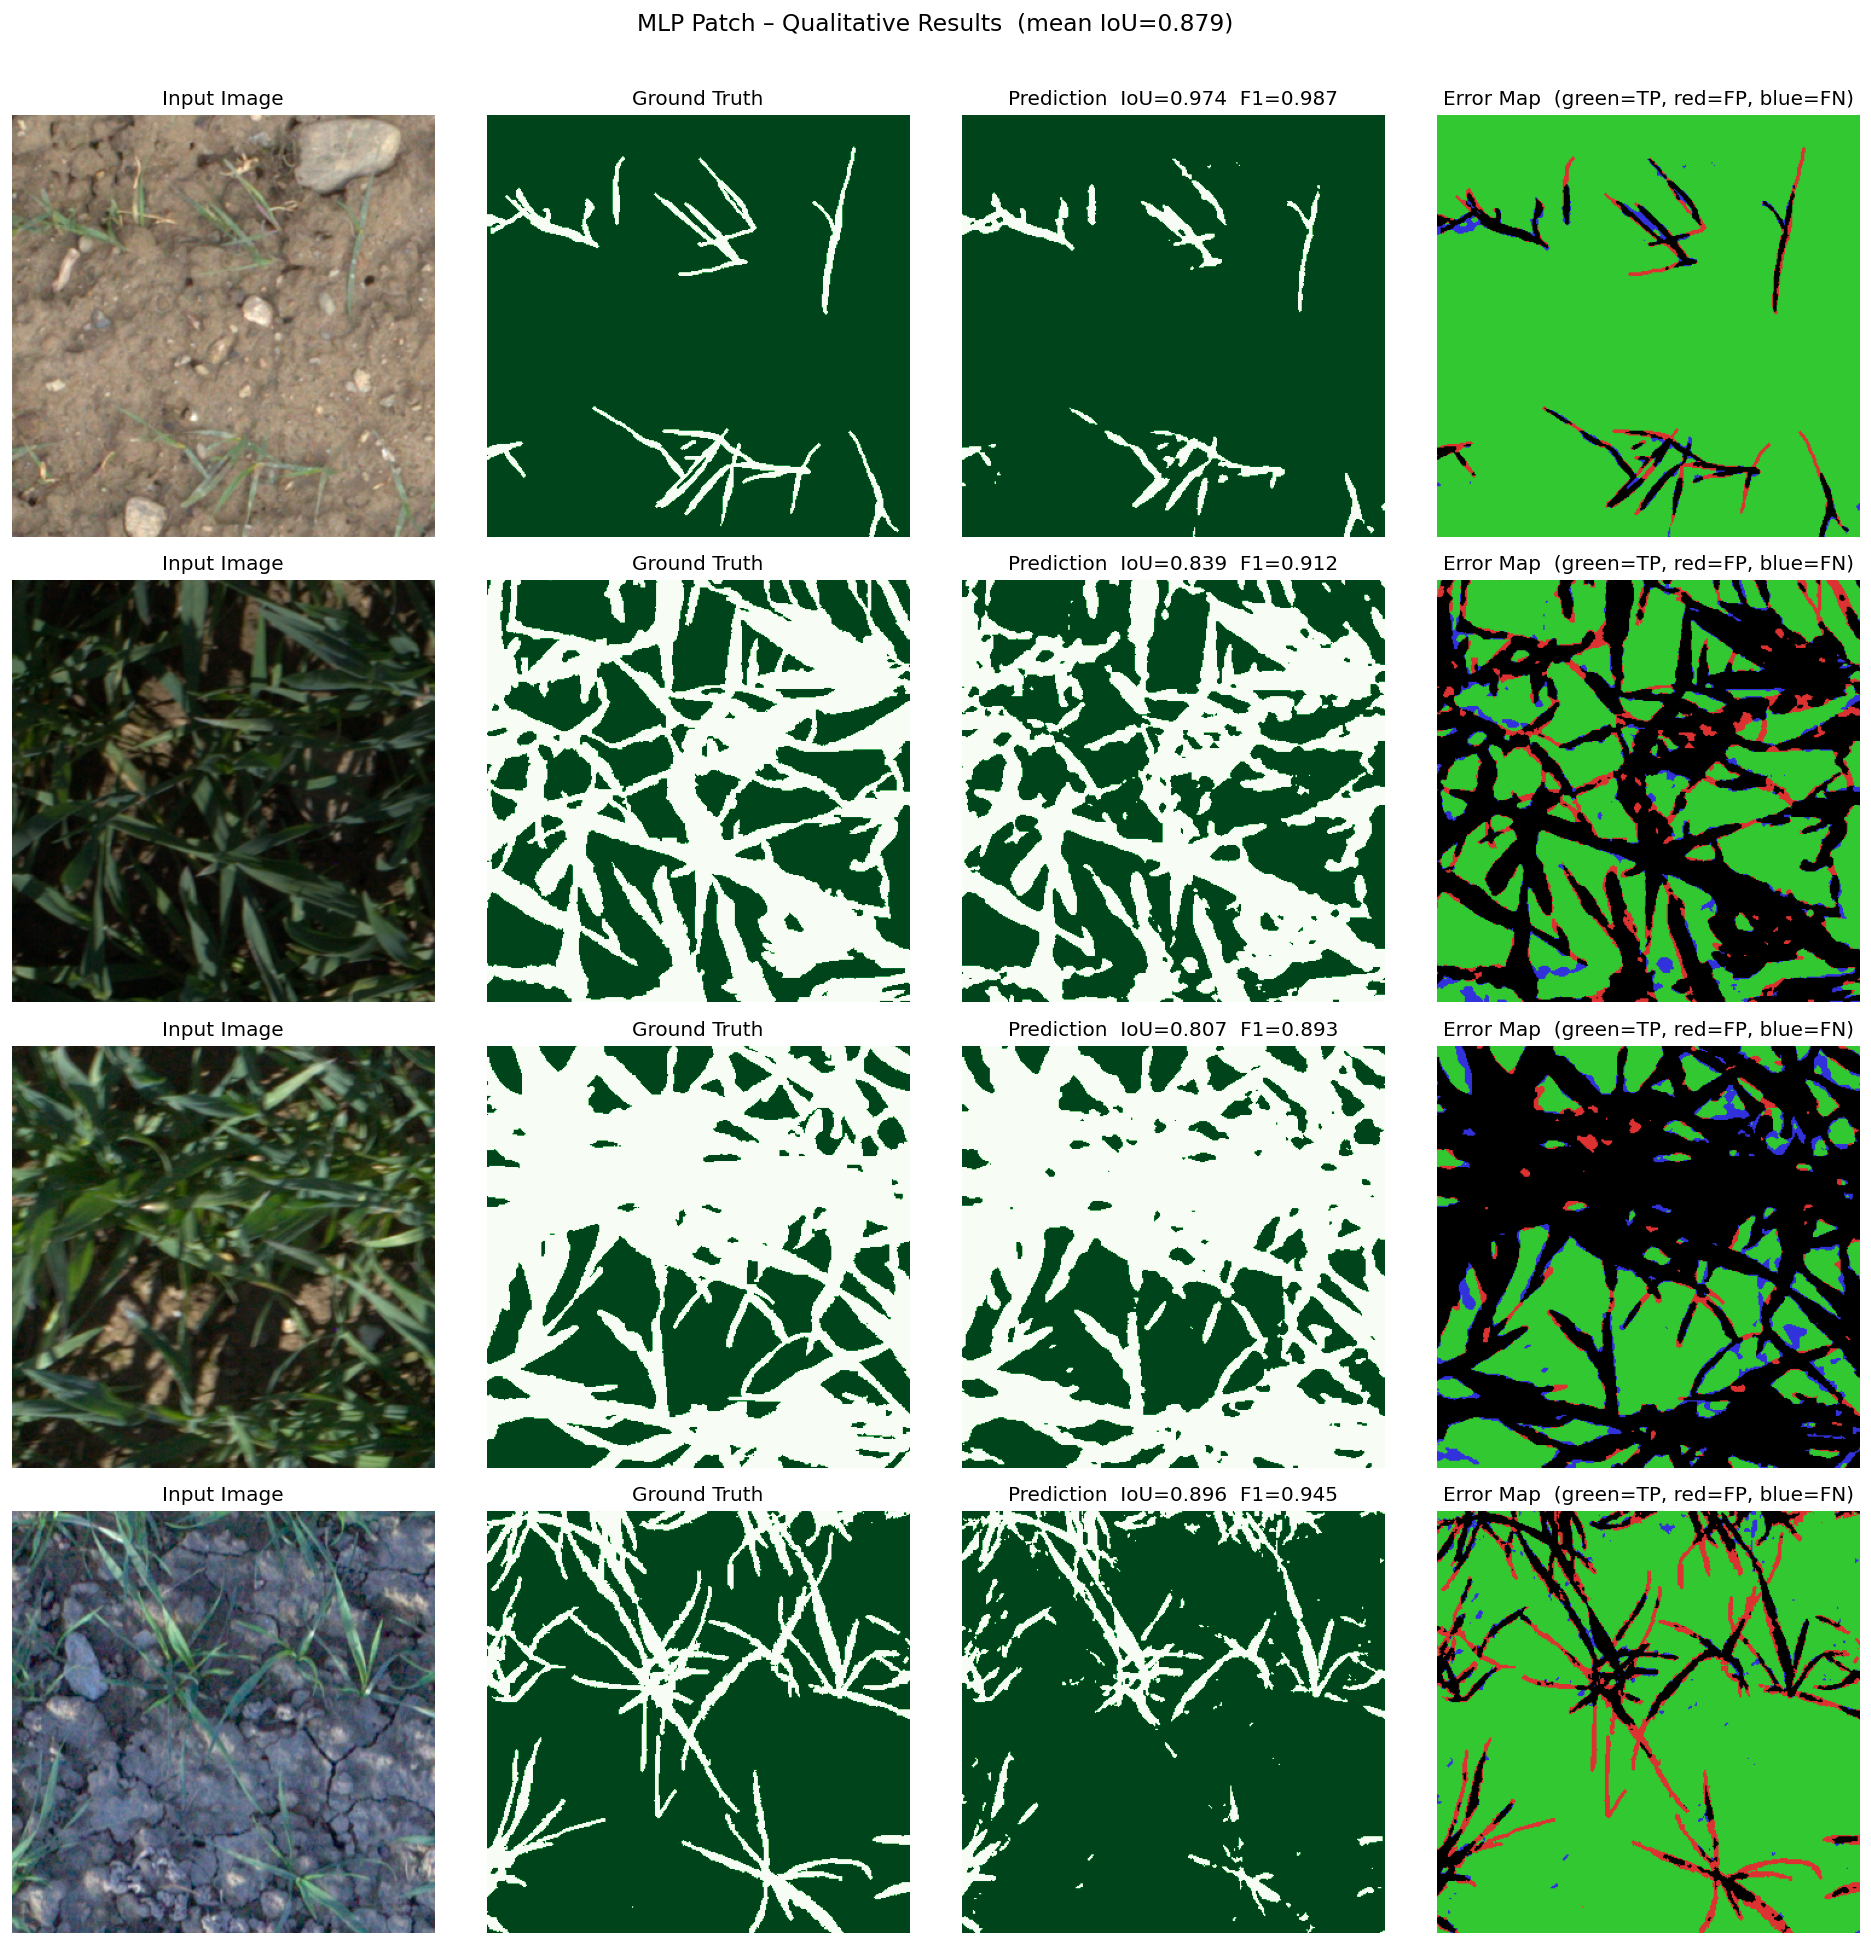

Per-image IoU: ['0.974', '0.839', '0.807', '0.896']
Mean image IoU: 0.8787


In [14]:
def predict_full_image(img_path, msk_path):
    """Dense inference on a full image."""
    img  = np.array(Image.open(img_path).convert('RGB'))
    mask = np.array(Image.open(msk_path).convert('L'))
    H, W = img.shape[:2]
    
    X, y_gt = extract_patches(img, mask, stride=1)
    X_s = scaler.transform(X)
    y_hat = mlp.predict(X_s).reshape(H, W)
    y_true = y_gt.reshape(H, W)
    
    return img, y_true, y_hat


# 4 evenly-spaced test images
vis_indices = np.linspace(0, min(MAX_TEST, len(test_pairs)) - 1, 4, dtype=int)

fig = plt.figure(figsize=(16, 4 * len(vis_indices)))
gs = gridspec.GridSpec(len(vis_indices), 4, figure=fig)

ious = []
for row, idx in enumerate(vis_indices):
    ip, mp = test_pairs[idx]
    img, y_true, y_hat = predict_full_image(ip, mp)
    
    local_iou = jaccard_score(y_true.flatten(), y_hat.flatten())
    local_f1  = f1_score(y_true.flatten(), y_hat.flatten())
    ious.append(local_iou)
    
    # FP=red, FN=blue, TP=green
    err = np.zeros((*y_true.shape, 3), dtype=np.uint8)
    err[(y_hat==1) & (y_true==0)] = [220, 50, 50]
    err[(y_hat==0) & (y_true==1)] = [50, 50, 220]
    err[(y_hat==1) & (y_true==1)] = [50, 200, 50]
    
    ax0 = fig.add_subplot(gs[row, 0])
    ax1 = fig.add_subplot(gs[row, 1])
    ax2 = fig.add_subplot(gs[row, 2])
    ax3 = fig.add_subplot(gs[row, 3])
    
    ax0.imshow(img)
    ax0.set_title('Input Image')
    ax0.axis('off')
    
    ax1.imshow(y_true, cmap='Greens')
    ax1.set_title('Ground Truth')
    ax1.axis('off')
    
    ax2.imshow(y_hat, cmap='Greens')
    ax2.set_title(f'Prediction  IoU={local_iou:.3f}  F1={local_f1:.3f}')
    ax2.axis('off')
    
    ax3.imshow(err)
    ax3.set_title('Error Map  (green=TP, red=FP, blue=FN)')
    ax3.axis('off')

plt.suptitle(f'MLP Patch – Qualitative Results  (mean IoU={np.mean(ious):.3f})', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('mlp_qualitative_results.png', bbox_inches='tight')
plt.show()

print(f'Per-image IoU: {[f"{v:.3f}" for v in ious]}')
print(f'Mean image IoU: {np.mean(ious):.4f}')

## 11. Comparison: Patch Size Ablation
Shows how the **receptive field** (patch size) affects performance — a key CNN design choice.

Patch size ablation (train=10, test=10)
-----------------------------
 Patch    Dim      F1     IoU
   7×7     147  0.9352  0.8782
  13×13    507  0.9279  0.8655
  17×17    867  0.9206  0.8529
  25×25   1875  0.9115  0.8374


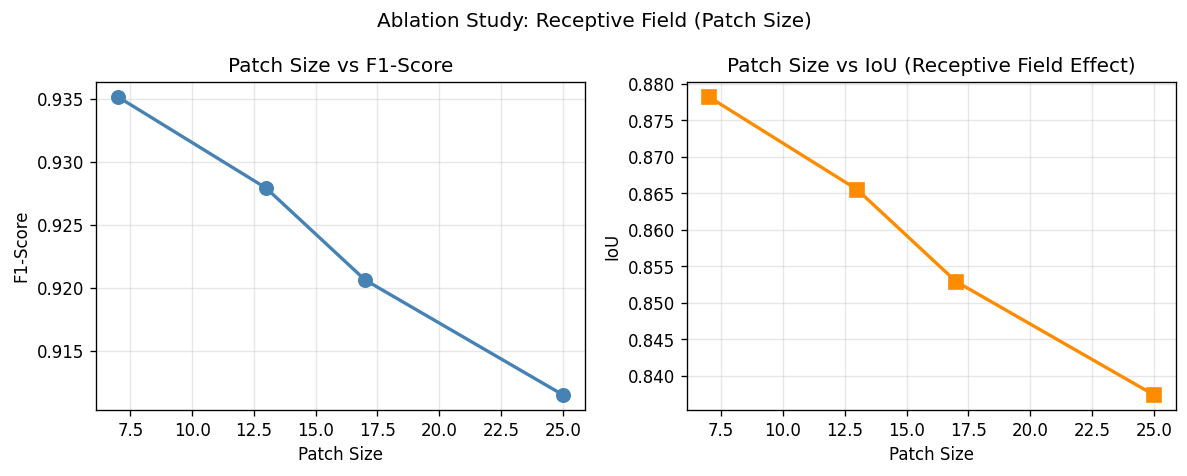

In [15]:
ABLATION_TRAIN = 10
ABLATION_TEST  = 10
patch_sizes = [7, 13, 17, 25]
results = []

def _extract(image, mask, stride=1, ps=7):
    H, W, _ = image.shape
    p = ps // 2
    img_f = image.astype(np.float32) / 255.0
    img_pad = np.pad(img_f, ((p,p),(p,p),(0,0)), mode='reflect')
    labs = (mask > 128).astype(np.int32)
    patches, ys = [], []
    for r in range(0, H, stride):
        for c in range(0, W, stride):
            patches.append(img_pad[r:r+ps, c:c+ps].flatten())
            ys.append(labs[r, c])
    return np.array(patches, dtype=np.float32), np.array(ys)

for ps in patch_sizes:
    Xtr, ytr = [], []
    for ip, mp in train_pairs[:ABLATION_TRAIN]:
        img  = np.array(Image.open(ip).convert('RGB'))
        msk  = np.array(Image.open(mp).convert('L'))
        x, y = _extract(img, msk, stride=6, ps=ps)
        Xtr.append(x); ytr.append(y)
    Xtr, ytr = np.vstack(Xtr), np.concatenate(ytr)

    Xte, yte = [], []
    for ip, mp in test_pairs[:ABLATION_TEST]:
        img  = np.array(Image.open(ip).convert('RGB'))
        msk  = np.array(Image.open(mp).convert('L'))
        x, y = _extract(img, msk, stride=4, ps=ps)
        Xte.append(x); yte.append(y)
    Xte, yte = np.vstack(Xte), np.concatenate(yte)

    sc_ = StandardScaler()
    Xtr_s = sc_.fit_transform(Xtr)
    Xte_s = sc_.transform(Xte)

    m = MLPClassifier(hidden_layer_sizes=(256,128), activation='relu', solver='adam',
                      max_iter=30, early_stopping=True, random_state=42, verbose=False)
    m.fit(Xtr_s, ytr)
    pred = m.predict(Xte_s)
    results.append({
        'patch_size': ps,
        'input_dim':  ps * ps * 3,
        'F1':         f1_score(yte, pred),
        'IoU':        jaccard_score(yte, pred),
    })

# Print summary table once at the end
header = f"{'Patch':>6}  {'Dim':>5}  {'F1':>6}  {'IoU':>6}"
print("Patch size ablation (train={}, test={})".format(ABLATION_TRAIN, ABLATION_TEST))
print("-" * len(header))
print(header)
for r in results:
    print(f"{r['patch_size']:>4}×{r['patch_size']:<2}  {r['input_dim']:>5}  "
          f"{r['F1']:>6.4f}  {r['IoU']:>6.4f}")

# Plot ablation
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ps_vals   = [r['patch_size'] for r in results]
f1_vals   = [r['F1']        for r in results]
iou_vals  = [r['IoU']       for r in results]

axes[0].plot(ps_vals, f1_vals, 'o-', color='steelblue',  linewidth=2, markersize=8)
axes[0].set_xlabel('Patch Size'); axes[0].set_ylabel('F1-Score')
axes[0].set_title('Patch Size vs F1-Score'); axes[0].grid(True, alpha=0.3)

axes[1].plot(ps_vals, iou_vals, 's-', color='darkorange', linewidth=2, markersize=8)
axes[1].set_xlabel('Patch Size'); axes[1].set_ylabel('IoU')
axes[1].set_title('Patch Size vs IoU (Receptive Field Effect)'); axes[1].grid(True, alpha=0.3)

plt.suptitle('Ablation Study: Receptive Field (Patch Size)', fontsize=12)
plt.tight_layout()
plt.savefig('mlp_ablation_patch_size.png', bbox_inches='tight')
plt.show()

## 12. Comparison with Method (SLIC + RF)
Summary comparison table.

In [18]:
#Fill in my former Method scores here after running slic_rf_svm_segmentation.ipynb(my original Method notebook)
if 'run_summary' in globals():
    method3_f1_text = f"{run_summary['f1']['mean']:.4f} ± {run_summary['f1']['std']:.4f}"
    method3_iou_text = f"{run_summary['iou']['mean']:.4f} ± {run_summary['iou']['std']:.4f}"
    method3_note = 'repeated protocol (fixed seeds, multi-run)'
else:
    method3_f1_text = f"{f1_score(y_test, y_pred):.4f}"
    method3_iou_text = f"{jaccard_score(y_test, y_pred):.4f}"
    method3_note = 'single-run evaluation'

comparison = {
    'Method': [
        'Baseline (Otsu Threshold)',
        'SLIC + Random Forest',
        'MLP Patch (Ours)'
    ],
    'Type': [
        'Traditional',
        'Machine Learning',
        'Deep Learning'
    ],
    'Features': [
        'None (intensity only)',
        'Hand-crafted (colour + LBP)',
        'Learned from raw pixels'
    ],
    'F1-Score': [
        '~0.80 (est.)',
        '0.957',
        method3_f1_text
    ],
    'IoU': [
        '~0.67 (est.)',
        '0.918',
        method3_iou_text
    ]
}

print('\n' + '='*80)
print(f"{'Method':<35} {'Type':<18} {'F1':>18} {'IoU':>18}")
print('-'*80)
for i in range(len(comparison['Method'])):
    print(f"{comparison['Method'][i]:<35} {comparison['Type'][i]:<18} "
          f"{comparison['F1-Score'][i]:>18} {comparison['IoU'][i]:>18}")
print('='*80)
print(f"MLP Patch results: {method3_note}")

print("""
Key insight: the MLP learns features directly from raw patches. SLIC + RF relies on
hand-crafted descriptors (ExG, LBP, HSV) and needs domain expertise to design them.
The tradeoff: MLP needs more data and compute but adapts to the data rather than
relying on predefined feature extractors.
""")


Method                              Type                               F1                IoU
--------------------------------------------------------------------------------
Baseline (Otsu Threshold)           Traditional              ~0.80 (est.)       ~0.67 (est.)
SLIC + Random Forest                Machine Learning                0.957              0.918
MLP Patch (Ours)                    Deep Learning         0.9408 ± 0.0040    0.8882 ± 0.0072
MLP Patch results: repeated protocol (fixed seeds, multi-run)

Key insight: the MLP learns features directly from raw patches. SLIC + RF relies on
hand-crafted descriptors (ExG, LBP, HSV) and needs domain expertise to design them.
The tradeoff: MLP needs more data and compute but adapts to the data rather than
relying on predefined feature extractors.



## 13. Discussion

### Why MLP Patch Classification?

This method follows the Feature-based pixel classification paradigm from Week 5 (Slide 16): extract a patch around each pixel, compute its features, and classify the centre pixel. The difference is that our MLP learns those features from raw data instead of relying on hand-crafted descriptors.

### Advantages

- Learns colour, texture, and context directly from pixels — no manual feature engineering required.
- Pixel-level operation gives fine-grained boundary control that superpixel methods cannot match.
- Receptive field is explicit: patch size is a single number you can tune.

### Limitations

- Inference is expensive — every pixel requires a separate forward pass, whereas a CNN processes the whole image in one.
- Predictions are independent per pixel, so the output can look noisy without spatial constraints.
- Receptive field is fixed. A convolutional network would build multi-scale context dynamically, which this architecture cannot do.

### Connection to the Spec Paper

Zenkl et al. (2022) used DeepLabV3+ on the EWS dataset. Our MLP classifier demonstrates the same underlying idea — learn from image patches — but without the convolutional encoder-decoder structure. It is a stripped-down version of that principle, useful as a baseline and as a bridge toward fully convolutional approaches.

| Parameter | Value |
|---|---|
| Method | MLP Patch Classification |
| Patch size | 17×17×3 = 867 input dims |
| Architecture | 512 → 256 → 128 → 2 (4 layers) |
| Optimiser | Adam (lr=1e-3) |
| Regularisation | L2 weight decay + early stopping |
| Train images | 30 (stride=4 sampling) |
| Test images | 48 (dense inference) |

All code is original. Dataset is from Zenkl et al. (2022), EWS. The method concept follows Farabet et al. (2013), *Learning Hierarchical Features for Scene Labeling*. Built with scikit-learn, scikit-image, NumPy, and Matplotlib.